In [1]:
import os
import io
import glob
import copy
import random
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

from torchvision import datasets, transforms, models
from torchvision.models import resnet18, ResNet18_Weights

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

seed = 42
rng = random.Random(seed)

Using device: cpu


In [2]:
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.247, 0.243, 0.261])
])

train_dataset_full = datasets.CIFAR10(root='./cifar-10-batches-py', train=True,
                                      download=True, transform=transform)
test_dataset_full = datasets.CIFAR10(root='./cifar-10-batches-py', train=False,
                                     download=True, transform=transform)

train_dataset = train_dataset_full
test_dataset = test_dataset_full

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("train - test dataset ready.")

Files already downloaded and verified
Files already downloaded and verified
train - test dataset ready.


In [3]:
def load_model(path="full_model.pth"):
    print("\nLoading pretrained ResNet18 model...")
    model = resnet18(weights=ResNet18_Weights.DEFAULT)

    # Modify final layer for 2 classes
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 10)

    # Freeze all layers except layer3, layer4, fc
    for param in model.parameters():
        param.requires_grad = False
    for layer in [model.layer3, model.layer4, model.fc]:
        for param in layer.parameters():
            param.requires_grad = True

    # Load fine-tuned weights if available
    if os.path.exists(path):
        model.load_state_dict(torch.load(path, map_location=device))
        print(f"Loaded fine-tuned weights from '{path}'")
    else:
        print(f"Warning: '{path}' not found. Model is not fine-tuned yet.")

    return model.to(device)


model = load_model()
model.eval()
model = model.to(device)


Loading pretrained ResNet18 model...
Loaded fine-tuned weights from 'full_model.pth'


/tmp/ipykernel_34053/4221293710.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(path, map_location=device))


In [4]:
class Encoder(nn.Module):
    def __init__(self, z_channels=512):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 128, 4, 2, 1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, 3, 1, 1),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 256, 4, 2, 1),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, z_channels, 3, 1, 1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.enc(x)

class Decoder(nn.Module):
    def __init__(self, z_channels=512):
        super().__init__()
        self.dec = nn.Sequential(
            nn.Conv2d(z_channels, 256, 3, 1, 1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(256, 256, 4, 2, 1),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 128, 3, 1, 1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 128, 4, 2, 1),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 3, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.dec(z)

class AutoEncoder(nn.Module):
    def __init__(self, z_channels=512):
        super().__init__()
        self.encoder = Encoder(z_channels)
        self.decoder = Decoder(z_channels)

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon

DeepAE = AutoEncoder().to(device)
DeepAE.load_state_dict(torch.load("deep_autoencoder.pth", map_location=device))
DeepAE.eval()

/tmp/ipykernel_34053/3610797748.py:62: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  DeepAE.load_state_dict(torch.load("deep_autoencoder.pth", map_location=device))


AutoEncoder(
  (encoder): Encoder(
    (enc): Sequential(
      (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU(inplace=True)
      (6): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (7): ReLU(inplace=True)
      (8): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (9): ReLU(inplace=True)
    )
  )
  (decoder): Decoder(
    (dec): Sequential(
      (0): Conv2d(512, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): ConvTranspose2d(256, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): Conv2d(256, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (5): ReLU(inplace=True)
      (6):

In [5]:
class MirrorBasicBlock(nn.Module):
    """Reverse of a ResNet BasicBlock, preserving residual skip."""
    def __init__(self, block):
        super().__init__()
        # Mirror convs
        self.deconv2 = self.mirror_conv(block.conv2)
        self.bn2 = nn.BatchNorm2d(block.conv2.in_channels)
        self.deconv1 = self.mirror_conv(block.conv1)
        self.bn1 = nn.BatchNorm2d(block.conv1.in_channels)
        self.relu = nn.ReLU(inplace=True)

        # Mirror downsample (if present)
        if block.downsample is not None:
            down = block.downsample[0]
            self.upsample = nn.Sequential(
                self.mirror_conv(down),
                nn.BatchNorm2d(down.in_channels)
            )
        else:
            self.upsample = None

    def mirror_conv(self, conv):
        """Create a ConvTranspose2d layer that mirrors a given Conv2d layer."""
        return nn.ConvTranspose2d(
            in_channels=conv.out_channels,
            out_channels=conv.in_channels,
            kernel_size=conv.kernel_size,
            stride=conv.stride,
            padding=conv.padding,
            output_padding=1 if conv.stride[0] > 1 else 0,
            bias=False,
        )

    def forward(self, x):
        identity = x
        out = self.deconv2(x)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.deconv1(out)
        out = self.bn1(out)

        if self.upsample is not None:
            identity = self.upsample(identity)

        out += identity
        out = self.relu(out)
        return out


In [6]:
class Encoder(nn.Module):
    def __init__(self, trained_model):
        super().__init__()
        self.features = nn.Sequential(
            trained_model.conv1,
            trained_model.bn1,
            trained_model.relu,
            trained_model.maxpool,
            trained_model.layer1,
            trained_model.layer2,
            trained_model.layer3
        )

    def forward(self, x):
        with torch.no_grad():
            return self.features(x)


encoder = Encoder(model).to(device)
encoder.eval()


Encoder(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

In [7]:
def denormalize(tensor):
    """Convert normalized tensor back to uint8 image (0–255)."""
    mean = torch.tensor([0.4914, 0.4822, 0.4465], device=tensor.device).view(3, 1, 1)
    std = torch.tensor([0.247, 0.243, 0.261], device=tensor.device).view(3, 1, 1)
    img = tensor * std + mean
    img = (img.clamp(0, 1) * 255).byte().permute(1, 2, 0).cpu().numpy()
    return img


def tensor_to_pil(tensor):
    """Convert tensor (C,H,W) -> PIL image."""
    return Image.fromarray(denormalize(tensor))


def get_file_size(img_pil, format="JPEG", quality=95):
    """Return file size in bytes when saving image."""
    buf = io.BytesIO()
    img_pil.save(buf, format=format, quality=quality)
    return buf.getbuffer().nbytes


def compress_to_target_size(img_tensor, target_bytes, step=0.001, min_q=5, max_q=100, min_bytes=None):
    """
    Compress an image tensor to JPEG until output size ≈ target_bytes.
    Ensures compressed size is not smaller than min_bytes if provided.
    Returns the compressed tensor and the quality used.
    """
    img_np = denormalize(img_tensor)
    pil_img = Image.fromarray(img_np)
    q_low, q_high = min_q, max_q
    best_img = pil_img
    best_size = None
    best_q = max_q

    while q_low <= q_high:
        q_mid = (q_low + q_high) // 2
        buf = io.BytesIO()
        pil_img.save(buf, format='JPEG', quality=q_mid)
        size = buf.getbuffer().nbytes

        # Enforce min_bytes
        if min_bytes is not None and size < min_bytes:
            q_low = q_mid + 1
            continue

        # Check if this is the closest so far
        if best_size is None or abs(size - target_bytes) < abs(best_size - target_bytes):
            best_img = Image.open(buf).convert("RGB")
            best_size = size
            best_q = q_mid

        if size > target_bytes:
            q_high = q_mid - 1
        elif size < target_bytes:
            q_low = q_mid + 1
        else:
            best_img = Image.open(buf).convert("RGB")
            best_size = size
            best_q = q_mid
            break

    return transforms.ToTensor()(best_img), best_q


In [8]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decode = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        return self.decode(x)

save_dir = "STanh_TargetAlpha"
decoder_path = glob.glob(os.path.join(save_dir, "decoder*.pth"))[0]

SimpleTanh = Decoder().to(device)
SimpleTanh.load_state_dict(torch.load(decoder_path, map_location=device))
SimpleTanh.eval()

/tmp/ipykernel_34053/67242978.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  SimpleTanh.load_state_dict(torch.load(decoder_path, map_location=device))


Decoder(
  (decode): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Tanh()
  )
)

In [9]:
class Decoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decode = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decode(x)

save_dir = "SSigmoid_TargetAlpha"
decoder_path = glob.glob(os.path.join(save_dir, "decoder*.pth"))[0]

SimpleSigmoid = Decoder().to(device)
SimpleSigmoid.load_state_dict(torch.load(decoder_path, map_location=device))
SimpleSigmoid.eval()

/tmp/ipykernel_34053/1570887492.py:22: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  SimpleSigmoid.load_state_dict(torch.load(decoder_path, map_location=device))


Decoder(
  (decode): Sequential(
    (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(32, 3, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Sigmoid()
  )
)

In [10]:
class Decoder(nn.Module):
    def __init__(self):
        super(Decoder, self).__init__()

        base = models.resnet18(weights=None)

        def mirror_layer(layer):
            blocks = [MirrorBasicBlock(b) for b in reversed(layer)]
            return nn.Sequential(*blocks)

        self.up3 = mirror_layer(base.layer3)
        self.up2 = mirror_layer(base.layer2)
        self.up1 = mirror_layer(base.layer1)

        # Mirror of initial conv (7x7 stride=2)
        self.final = nn.ConvTranspose2d(
            64, 3, kernel_size=7, stride=2, padding=3, output_padding=1
        )

        # Extra step: bring from 16×16 -> 32×32
        self.upsample_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(3, 3, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.up3(x)
        x = self.up2(x)
        x = self.up1(x)
        x = self.final(x)
        x = self.upsample_final(x)
        return x
save_dir = "MRTanh_TargetAlpha"
decoder_path = glob.glob(os.path.join(save_dir, "decoder*.pth"))[0]

MRTanh = Decoder().to(device)
MRTanh.load_state_dict(torch.load(decoder_path, map_location=device))
MRTanh.eval()


/tmp/ipykernel_34053/927344294.py:38: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  MRTanh.load_state_dict(torch.load(decoder_path, map_location=device))


Decoder(
  (up3): Sequential(
    (0): MirrorBasicBlock(
      (deconv2): ConvTranspose2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (deconv1): ConvTranspose2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (1): MirrorBasicBlock(
      (deconv2): ConvTranspose2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (deconv1): ConvTranspose2d(256, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (upsample): Seq

In [11]:
class Decoder(nn.Module):
    def __init__(self):
        super(Decoder, self).__init__()

        base = models.resnet18(weights=None)

        def mirror_layer(layer):
            blocks = [MirrorBasicBlock(b) for b in reversed(layer)]
            return nn.Sequential(*blocks)

        self.up3 = mirror_layer(base.layer3)
        self.up2 = mirror_layer(base.layer2)
        self.up1 = mirror_layer(base.layer1)

        # Mirror of initial conv (7x7 stride=2)
        self.final = nn.ConvTranspose2d(
            64, 3, kernel_size=7, stride=2, padding=3, output_padding=1
        )

        # Extra step: bring from 16×16 -> 32×32
        self.upsample_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(3, 3, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.up3(x)
        x = self.up2(x)
        x = self.up1(x)
        x = self.final(x)
        x = self.upsample_final(x)
        return x

save_dir = "MRSigmoid_TargetAlpha"
decoder_path = glob.glob(os.path.join(save_dir, "decoder*.pth"))[0]

MRSigmoid = Decoder().to(device)
MRSigmoid.load_state_dict(torch.load(decoder_path, map_location=device))
MRSigmoid.eval()


/tmp/ipykernel_34053/2836956325.py:39: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  MRSigmoid.load_state_dict(torch.load(decoder_path, map_location=device))


Decoder(
  (up3): Sequential(
    (0): MirrorBasicBlock(
      (deconv2): ConvTranspose2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (deconv1): ConvTranspose2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
    )
    (1): MirrorBasicBlock(
      (deconv2): ConvTranspose2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (deconv1): ConvTranspose2d(256, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (upsample): Seq

      variant  true_label  pred  accuracy        ce  size_bytes  jpeg_q
0    original           1     1         1  0.267724        1476     NaN
1       lossy           1     4         0  7.296151        1045    92.0
2      deepae           1     3         0  1.305678        1362     NaN
3  simpletanh           1     1         1  0.003627        1191     NaN
4      mrtanh           1     1         1  0.000203        1272     NaN


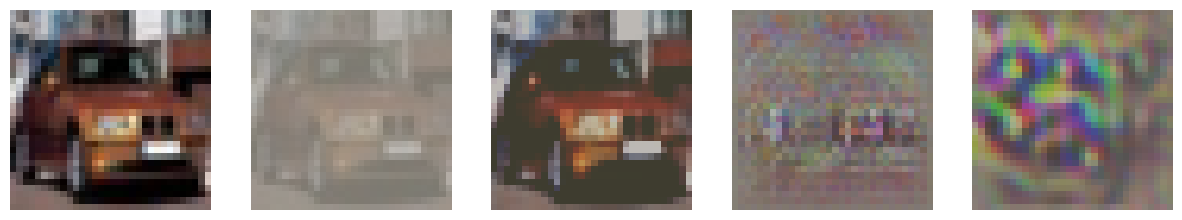

In [166]:
# Pick a random sample from the test dataset
rng = np.random.RandomState()  # different each run
idx = rng.randint(len(test_dataset))
img, label = test_dataset[idx]
img_tensor = img.unsqueeze(0).to(device)
label = torch.tensor([label], device=device)

# Original
orig_pil = tensor_to_pil(img_tensor[0])

# Compute target bytes as avg size of SimpleTanh & MRTanh reconstructions
with torch.no_grad():
    simpletanh_recon = SimpleTanh(encoder(img_tensor))
    mrtanh_recon = MRTanh(encoder(img_tensor))

    size_simpletanh = get_file_size(tensor_to_pil(simpletanh_recon[0]))
    size_mrtanh = get_file_size(tensor_to_pil(mrtanh_recon[0]))
    avg_size = int((size_simpletanh + size_mrtanh) / 2)

# Lossy compression (returns Q as well)
min_bytes = max(size_simpletanh, size_mrtanh)  # ensure not smaller than components
lossy_tensor, lossy_q = compress_to_target_size(img_tensor[0], avg_size, min_bytes=min_bytes)
lossy_tensor = lossy_tensor.unsqueeze(0).to(device)
lossy_size = get_file_size(tensor_to_pil(lossy_tensor[0]))

# Reconstructions
with torch.no_grad():
    deepae_tensor = DeepAE(img_tensor)
    deepae_size = get_file_size(tensor_to_pil(deepae_tensor[0]))

    simpletanh_tensor = simpletanh_recon
    simpletanh_size = size_simpletanh

    mrtanh_tensor = mrtanh_recon
    mrtanh_size = size_mrtanh

# Prepare outputs
outputs = {
    "original": (img_tensor, get_file_size(orig_pil), None),
    "lossy": (lossy_tensor, lossy_size, lossy_q),
    "deepae": (deepae_tensor, deepae_size, None),
    "simpletanh": (simpletanh_tensor, simpletanh_size, None),
    "mrtanh": (mrtanh_tensor, mrtanh_size, None)
}

# Evaluate each
records = []
for name, (out, size, q) in outputs.items():
    logits = model(out)
    pred = torch.argmax(logits, dim=1)
    ce = F.cross_entropy(logits, label).item()
    acc = int(pred.item() == label.item())
    records.append([name, label.item(), pred.item(), acc, ce, size, q])

# DataFrame
df = pd.DataFrame(records, columns=["variant", "true_label", "pred", "accuracy", "ce", "size_bytes", "jpeg_q"])
print(df)

# Only show images if lossy fails but both SimpleTanh & MRTanh succeed
lossy_acc = df.loc[df["variant"]=="lossy", "accuracy"].item()
simpletanh_acc = df.loc[df["variant"]=="simpletanh", "accuracy"].item()
mrtanh_acc = df.loc[df["variant"]=="mrtanh", "accuracy"].item()

if lossy_acc == 0 and simpletanh_acc == 1 and mrtanh_acc == 1:
    fig, axes = plt.subplots(1, len(outputs), figsize=(15,3))
    axes = np.array(axes).reshape(-1)  # ensures iterable even if len=1
    for ax, (out, _, _) in zip(axes, outputs.values()):
        ax.imshow(denormalize(out[0]))
        ax.axis("off")
    plt.show()


      variant  true_label  pred  accuracy        ce  size_bytes  jpeg_q
0    original           5     5         1  0.001681        1382     NaN
1       lossy           5     3         0  1.841496        1015    93.0
2      deepae           5     5         1  0.008476        1331     NaN
3  simpletanh           5     5         1  0.000125        1125     NaN
4      mrtanh           5     5         1  0.000018        1258     NaN


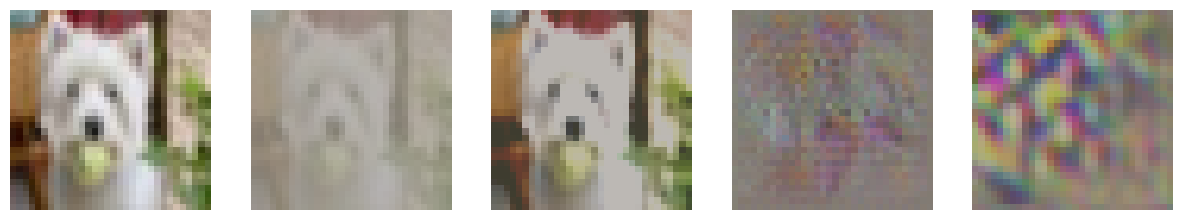

In [92]:
# Pick a random sample from the test dataset
rng = np.random.RandomState()  # different each run
idx = rng.randint(len(test_dataset))
img, label = test_dataset[idx]
img_tensor = img.unsqueeze(0).to(device)
label = torch.tensor([label], device=device)

# Original
orig_pil = tensor_to_pil(img_tensor[0])

# Compute target bytes as avg size of SimpleTanh & MRTanh reconstructions
with torch.no_grad():
    simpletanh_recon = SimpleTanh(encoder(img_tensor))
    mrtanh_recon = MRTanh(encoder(img_tensor))

    size_simpletanh = get_file_size(tensor_to_pil(simpletanh_recon[0]))
    size_mrtanh = get_file_size(tensor_to_pil(mrtanh_recon[0]))
    avg_size = int((size_simpletanh + size_mrtanh) / 2)

# Lossy compression (now returns Q as well)
min_bytes = max(size_simpletanh, size_mrtanh)  # ensure not smaller than components
lossy_tensor, lossy_q = compress_to_target_size(img_tensor[0], avg_size, min_bytes=min_bytes)
lossy_tensor = lossy_tensor.unsqueeze(0).to(device)
lossy_size = get_file_size(tensor_to_pil(lossy_tensor[0]))

# Reconstructions
with torch.no_grad():
    deepae_tensor = DeepAE(img_tensor)
    deepae_size = get_file_size(tensor_to_pil(deepae_tensor[0]))

    simpletanh_tensor = simpletanh_recon
    simpletanh_size = size_simpletanh

    mrtanh_tensor = mrtanh_recon
    mrtanh_size = size_mrtanh

# Prepare outputs
outputs = {
    "original": (img_tensor, get_file_size(orig_pil), None),
    "lossy": (lossy_tensor, lossy_size, lossy_q),
    "deepae": (deepae_tensor, deepae_size, None),
    "simpletanh": (simpletanh_tensor, simpletanh_size, None),
    "mrtanh": (mrtanh_tensor, mrtanh_size, None)
}

# Evaluate each
records = []
for name, (out, size, q) in outputs.items():
    logits = model(out)
    pred = torch.argmax(logits, dim=1)
    ce = F.cross_entropy(logits, label).item()
    acc = int(pred.item() == label.item())
    records.append([name, label.item(), pred.item(), acc, ce, size, q])

# DataFrame
df = pd.DataFrame(records, columns=["variant", "true_label", "pred", "accuracy", "ce", "size_bytes", "jpeg_q"])
print(df)

# Only show images if lossy prediction is wrong
lossy_acc = df.loc[df["variant"]=="lossy", "accuracy"].item()
simplesigmoid_acc = df.loc[df["variant"]=="simpletanh", "accuracy"].item()
mrsigmoid_acc = df.loc[df["variant"]=="mrtanh", "accuracy"].item()
if lossy_acc == 0:
    fig, axes = plt.subplots(1, len(outputs), figsize=(15,3))
    axes = np.array(axes).reshape(-1)  # ensures iterable even if len=1
    for ax, (out, _, _) in zip(axes, outputs.values()):
        ax.imshow(denormalize(out[0]))
        ax.axis("off")
    plt.show()
